# RNN & LSTM for sentiment analysis — IMDB

**Bài tập:** so sánh SimpleRNN, LSTM, SVM và Logistic Regression trên 50.000
đánh giá IMDB.

Mặc định `RUN_MODE = "full"`. Chế độ `"quick"` chỉ kiểm tra pipeline với
1.000 train / 200 validation / 1.000 test và 1 epoch; không dùng để kết luận.
Thời gian huấn luyện phụ thuộc phần cứng local và số epoch early stopping.
Phần môi trường ghi lại CPU/GPU thực tế của lần chạy.

Notebook bao gồm: lý thuyết, phương pháp,
mã, kết quả, phân tích. Các file CSV, hình PNG,
mô hình và thông tin tái lập được lưu trong `results/full/` hoặc
`results/quick/`, đồng thời có ZIP trong `results/`.


## 1. Thiết kế thí nghiệm và cấu hình


- Làm sạch HTML, giải mã HTML entities, chuyển chữ thường, mở rộng phủ định
  như “isn't” → “is not”, thay dấu câu bằng khoảng trắng. Không bỏ stopword.
- Chỉ `fit` TF-IDF và `adapt` từ vựng trên train. Validation và test chỉ transform.
- Baseline: TF-IDF unigram/bigram, tối đa 20.000 đặc trưng, `min_df=2`,
  `sublinear_tf=True`. Logistic Regression và LinearSVC thử $C\in\{0.1,1,10\}$;
  chọn F1 validation cao nhất, hòa thì chọn C nhỏ hơn. Không refit trên train+val.
- Mạng: Embedding 128 → SimpleRNN/LSTM 64 → Dropout 0,5 → Dense sigmoid.
  Từ vựng chung tối đa 20.000 token (gồm padding/OOV), chuỗi 300 token,
  cắt phần cuối, padding cuối, `mask_zero=True`. Embedding học từ đầu.
- Adam learning rate 0,001, `clipnorm=1.0`, binary cross-entropy, batch 128,
  tối đa 10 epoch. Early stopping theo validation loss, patience 2,
  khôi phục trọng số tốt nhất. Hai mạng đặt lại cùng seed 42 trước khi tạo.
- LSTM dùng tanh/sigmoid, `recurrent_dropout=0`, không unroll, có bias và
  padding cuối để tương thích cuDNN khi GPU/runtime hỗ trợ.
- Dùng Accuracy, Precision, Recall, F1 (positive là lớp 1), ROC-AUC và confusion
  matrix. Ngưỡng dự đoán là 0,5 cho sigmoid/Logistic Regression, 0 cho SVM.
  ROC-AUC dùng xác suất hoặc margin của SVM, không dùng nhãn cứng.
- Chỉ tính kết quả test sau khi chọn C và trọng số mạng bằng validation.
  Theo dõi loss/accuracy train và validation để thảo luận overfitting.

TF-IDF dùng toàn bộ đánh giá, mạng chỉ dùng 300 token đầu. Đây là so sánh các
pipeline thực tế, chưa cô lập riêng ảnh hưởng của kiến trúc. Thời gian fit không
gồm tiền xử lý và đánh giá test cuối cùng; baseline cộng thời gian cả ba giá trị C, mạng cộng
các epoch đã chạy. Thời gian tạo đặc trưng được ghi riêng. Baseline chạy CPU;
mạng dùng GPU khi có. So sánh thời gian phụ thuộc phần cứng, không chứng minh
một thuật toán có độ phức tạp thấp hơn. Một seed chưa đo được độ biến thiên
giữa các lần chạy và không đủ để khẳng định ý nghĩa thống kê.



Chỉ cần sửa `RUN_MODE` ở ô dưới để đổi chế độ. Giữ `full` cho bài nộp.

**Sau khi đổi `RUN_MODE`, chọn Run All từ đầu notebook để tính lại số mẫu, số epoch và đường dẫn xuất kết quả. Mở notebook từ thư mục gốc dự án.**

In [1]:
RUN_MODE = "full"  # "full" hoặc "quick"
SEED = 42
MAX_TOKENS = 20_000
SEQUENCE_LENGTH = 300
EMBEDDING_DIM = 128
RECURRENT_UNITS = 64
DROPOUT = 0.5
BATCH_SIZE = 128
LEARNING_RATE = 0.001
C_VALUES = [0.1, 1.0, 10.0]
assert RUN_MODE in {"full", "quick"}
MAX_EPOCHS = 10 if RUN_MODE == "full" else 1

## 2. Thư viện và môi trường

Trong Terminal/PowerShell tại thư mục dự án, cài thư viện bằng môi trường
Python dùng làm kernel của notebook:

```powershell
python -m pip install -r requirements.txt
```

Trong VS Code, mở notebook và chọn **Select Kernel → Python Environments**.
Chọn **Run All** để chạy và **Ctrl+S** để lưu các output.

Nếu dùng giao diện Jupyter trên trình duyệt local, cài và mở thêm:

```powershell
python -m pip install notebook
python -m notebook
```

Mở notebook chính từ thư mục gốc dự án để các đường dẫn `data/` và `results/`
trỏ đúng vị trí. Kernel có thể dùng CPU; phần môi trường bên dưới ghi nhận
thiết bị thực tế. Nếu vừa cài thư viện, khởi động lại kernel rồi chạy từ đầu.

In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import sys, re, html, json, tarfile, hashlib, shutil, platform, time, urllib.request
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, roc_auc_score, ConfusionMatrixDisplay)
from IPython.display import display, Markdown, FileLink

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Giới hạn số luồng CPU cho kiểm tra nhỏ trên máy cá nhân.
if RUN_MODE == "quick":
    try:
        tf.config.threading.set_intra_op_parallelism_threads(4)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print("TensorFlow đã khởi tạo; giữ cấu hình luồng CPU hiện tại.")
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "results" / RUN_MODE
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
for directory in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
gpus = tf.config.list_physical_devices("GPU")
gpu_names = [tf.config.experimental.get_device_details(g).get("device_name", g.name)
             for g in gpus]
versions = {name: importlib.metadata.version(name) for name in
            ["tensorflow", "keras", "scikit-learn", "numpy", "pandas",
             "matplotlib", "pyarrow", "joblib"]}
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "mode": RUN_MODE, "python": sys.version, "platform": platform.platform(),
    "cpu": platform.processor() or platform.machine(), "cpu_count": os.cpu_count(),
    "gpu": gpu_names, "baseline_device": "CPU",
    "neural_device": "GPU" if gpus else "CPU", "versions": versions,
    "deterministic_ops": True,
}
print("Chế độ:", RUN_MODE.upper(), "| GPU:", gpu_names or "không có — dùng CPU")
display(pd.Series(versions, name="Phiên bản").to_frame())
if RUN_MODE == "quick":
    display(Markdown("**KIỂM TRA NHANH — kết quả không đại diện cho toàn bộ IMDB.**"))

Chế độ: FULL | GPU: không có — dùng CPU


,Phiên bản
tensorflow,2.21.0
keras,3.14.0
scikit-learn,1.7.2
numpy,2.3.3
pandas,2.3.3
matplotlib,3.10.7
pyarrow,22.0.0
joblib,1.5.2


## 3. Dữ liệu IMDB và nguồn dữ liệu


Phân loại một đánh giá phim tiếng Anh thành negative (0) hoặc positive (1),
so sánh SimpleRNN, LSTM với hai phương pháp truyền thống Logistic Regression
và SVM tuyến tính. Các mô hình được huấn luyện lại trên cùng cách chia dữ liệu.

IMDB Large Movie Review Dataset gồm 50.000 đánh giá có nhãn, cân bằng hai lớp.
Giữ nguyên 25.000 mẫu test chính thức; tách phân tầng 25.000 mẫu train thành
20.000 train và 5.000 validation với seed 42. Không dùng 50.000 mẫu không nhãn.


Ưu tiên file Stanford `.tar.gz` đã tải hoặc tải từ máy chủ gốc. Nếu kết nối thất bại, dùng hai split Parquet từ kho Stanford NLP trên Hugging Face. Quy ước `0 = negative`, `1 = positive`; chỉ dùng 50.000 mẫu có nhãn.

In [3]:
STANFORD_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
HF_BASE = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/"

def download_file(url, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(destination.suffix + ".part")
    print("Đang tải:", url, flush=True)
    try:
        with urllib.request.urlopen(url, timeout=30) as response, partial.open("wb") as out:
            shutil.copyfileobj(response, out, length=1024 * 1024)
        partial.replace(destination)
    finally:
        partial.unlink(missing_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_stanford_archive(archive_path):
    rows = []
    # Đọc trực tiếp văn bản, không giải nén đường dẫn ra filesystem.
    with tarfile.open(archive_path, "r:gz") as archive:
        for member in archive:
            parts = PurePosixPath(member.name).parts
            if (not member.isfile() or len(parts) != 4 or parts[0] != "aclImdb"
                    or parts[1] not in {"train", "test"}
                    or parts[2] not in {"pos", "neg"} or not parts[3].endswith(".txt")):
                continue
            with archive.extractfile(member) as stream:
                text = stream.read().decode("utf-8")
            rows.append({"review_id": "/".join(parts[1:]), "official_split": parts[1],
                         "text": text, "label": int(parts[2] == "pos")})
    return pd.DataFrame(rows).sort_values("review_id").reset_index(drop=True)

def load_imdb():
    archive = DATA_DIR / "aclImdb_v1.tar.gz"
    mirror_files = {s: DATA_DIR / "stanfordnlp_imdb" / f"{s}.parquet"
                    for s in ["train", "test"]}
    if not archive.exists() and not all(p.exists() for p in mirror_files.values()):
        try:
            download_file(STANFORD_URL, archive)
        except Exception as exc:
            print("Máy chủ Stanford chưa truy cập được:", type(exc).__name__)
            print("Chuyển sang bản Stanford NLP giữ split train/test.")
    if archive.exists():
        frame = read_stanford_archive(archive)
        provenance = {"source": "Stanford raw archive", "urls": [STANFORD_URL],
                      "sha256": {archive.name: sha256_file(archive)}}
    else:
        frames, urls = [], []
        for split, path in mirror_files.items():
            url = HF_BASE + f"{split}-00000-of-00001.parquet"
            urls.append(url)
            if not path.exists():
                download_file(url, path)
            part = pd.read_parquet(path)[["text", "label"]].reset_index(drop=True)
            part["review_id"] = [f"{split}/{i:05d}" for i in range(len(part))]
            part["official_split"] = split
            frames.append(part)
        frame = pd.concat(frames, ignore_index=True)
        provenance = {"source": "stanfordnlp/imdb Parquet (official splits)",
                      "urls": urls,
                      "sha256": {s: sha256_file(p) for s, p in mirror_files.items()}}
    assert len(frame) == 50_000 and frame.review_id.is_unique
    assert frame.text.map(lambda x: isinstance(x, str) and bool(x.strip())).all()
    assert set(frame.label.unique()) == {0, 1}
    for split in ["train", "test"]:
        counts = frame.loc[frame.official_split.eq(split), "label"].value_counts().to_dict()
        assert counts == {0: 12_500, 1: 12_500}, (split, counts)
    return frame, provenance

raw_df, provenance = load_imdb()
environment["dataset"] = provenance
print("Nguồn:", provenance["source"])
display(pd.crosstab(raw_df.official_split, raw_df.label))

Nguồn: stanfordnlp/imdb Parquet (official splits)


label,0,1
official_split,,
test,12500,12500
train,12500,12500


## 4. Chia train/validation, làm sạch và kiểm tra dữ liệu
Tách validation trước mọi bước học từ vựng. Quick chỉ lấy mẫu phân tầng từ ba tập đã tách, giữ nguyên ranh giới train/test chính thức.

Kiểm tra thêm hash nội dung trước/sau làm sạch vì ID khác nhau vẫn có thể
chứa cùng đánh giá. Giữ split benchmark và báo số trùng; đánh giá phụ trên
các hàng test không trùng train/validation dùng cùng mô hình đã chọn.

,representation,left_split,right_split,shared_unique_texts,left_rows,right_rows
0,raw,train,validation,34,36,35
1,raw,train,test,99,99,99
2,raw,validation,test,24,24,24
3,clean,train,validation,36,38,37
4,clean,train,test,99,99,99
5,clean,validation,test,24,24,24


Test trùng nội dung train/validation sau làm sạch: 123 / 25000


,split,samples,negative,positive,mean_tokens,p95_tokens,truncated_fraction
0,train,20000,10000,10000,237.6262,604.00,0.2338
1,validation,5000,2500,2500,240.8070,626.05,0.2408
2,test,25000,12500,12500,232.8593,593.00,0.2244


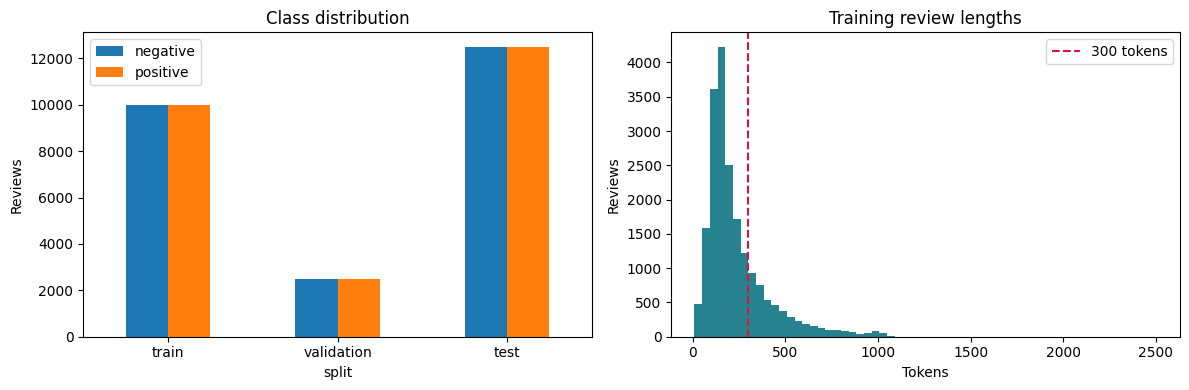

In [4]:
def clean_text(text):
    text = html.unescape(str(text)).lower().replace("’", "'")
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"<[^>]*>", " ", text)
    for contraction, expanded in [("can't", "can not"), ("won't", "will not"),
                                   ("shan't", "shall not")]:
        text = re.sub(r"\b" + re.escape(contraction) + r"\b", expanded, text)
    text = re.sub(r"n\'t\b", " not", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return " ".join(text.split())

assert clean_text("<br />I can't say it isn't good! &amp;") == "i can not say it is not good"
official_train = raw_df[raw_df.official_split.eq("train")].copy()
official_test = raw_df[raw_df.official_split.eq("test")].copy()
train_df, val_df = train_test_split(official_train, test_size=0.2,
                                   stratify=official_train.label, random_state=SEED)
test_df = official_test.copy()

def stratified_subset(frame, n):
    if len(frame) <= n:
        return frame.copy()
    subset, _ = train_test_split(frame, train_size=n, stratify=frame.label,
                                 random_state=SEED)
    return subset.copy()

if RUN_MODE == "quick":
    train_df = stratified_subset(train_df, 1000)
    val_df = stratified_subset(val_df, 200)
    test_df = stratified_subset(test_df, 1000)
splits = {"train": train_df, "validation": val_df, "test": test_df}
expected_sizes = [20_000, 5_000, 25_000] if RUN_MODE == "full" else [1000, 200, 1000]
for (split, frame), expected in zip(splits.items(), expected_sizes):
    frame.reset_index(drop=True, inplace=True)
    frame["clean_text"] = frame.text.map(clean_text)
    frame["n_tokens"] = frame.clean_text.str.split().str.len()
    assert len(frame) == expected
    assert frame.label.value_counts().to_dict() == {0: expected // 2, 1: expected // 2}
    assert frame.n_tokens.gt(0).all()
id_sets = [set(frame.review_id) for frame in splits.values()]
assert all(id_sets[i].isdisjoint(id_sets[j]) for i in range(3) for j in range(i + 1, 3))
assert train_df.official_split.eq("train").all() and val_df.official_split.eq("train").all()
assert test_df.official_split.eq("test").all()


# ID khác nhau vẫn có thể chứa cùng văn bản: kiểm kê cả trước/sau làm sạch.
# Giữ split benchmark; không dùng test để đổi C, checkpoint hay ngưỡng.
overlap_rows = []
for representation, column in [("raw", "text"), ("clean", "clean_text")]:
    fingerprints = {
        split: frame[column].map(lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest())
        for split, frame in splits.items()
    }
    split_names = list(splits)
    for i, left in enumerate(split_names):
        for right in split_names[i + 1:]:
            shared = set(fingerprints[left]) & set(fingerprints[right])
            overlap_rows.append({
                "representation": representation, "left_split": left, "right_split": right,
                "shared_unique_texts": len(shared),
                "left_rows": int(fingerprints[left].isin(shared).sum()),
                "right_rows": int(fingerprints[right].isin(shared).sum()),
            })
content_overlap = pd.DataFrame(overlap_rows)
content_overlap.to_csv(OUTPUT_DIR / "content_overlap.csv", index=False, encoding="utf-8-sig")
display(content_overlap)
development_hashes = set(fingerprints["train"]) | set(fingerprints["validation"])
test_df["seen_in_development"] = fingerprints["test"].isin(development_hashes).to_numpy()
print("Test trùng nội dung train/validation sau làm sạch:",
      int(test_df.seen_in_development.sum()), "/", len(test_df))
manifest = pd.concat([frame[["review_id", "official_split", "label"]].assign(split=split)
                      for split, frame in splits.items()], ignore_index=True)
manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False, encoding="utf-8-sig")
split_summary = pd.DataFrame([
    {"split": split, "samples": len(frame), "negative": int(frame.label.eq(0).sum()),
     "positive": int(frame.label.eq(1).sum()), "mean_tokens": frame.n_tokens.mean(),
     "p95_tokens": frame.n_tokens.quantile(0.95),
     "truncated_fraction": frame.n_tokens.gt(SEQUENCE_LENGTH).mean()}
    for split, frame in splits.items()])
display(split_summary.round(4))
split_summary.to_csv(OUTPUT_DIR / "data_summary.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_summary.set_index("split")[["negative", "positive"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Class distribution", ylabel="Reviews")
axes[1].hist(train_df.n_tokens, bins=60, color="#26828e")
axes[1].axvline(SEQUENCE_LENGTH, color="crimson", linestyle="--", label=f"{SEQUENCE_LENGTH} tokens")
axes[1].set(title="Training review lengths", xlabel="Tokens", ylabel="Reviews")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "data_overview.png", dpi=160)
plt.show()

## 5. Cơ sở lý thuyết

### TF-IDF, Logistic Regression và SVM

TF-IDF kết hợp tần suất từ trong tài liệu với độ hiếm trong tập train.
Với `sublinear_tf=True`, TF của từ xuất hiện được biến đổi thành
$1+\log(tf)$. IDF mặc định có làm trơn:
$\mathrm{idf}(t)=\log((1+N)/(1+df(t)))+1$, trong đó $N$ là số văn bản train
và $df(t)$ là số văn bản train chứa từ/cụm từ $t$. Trọng số TF-IDF bằng
TF đã biến đổi nhân IDF, sau đó cả vector văn bản được chuẩn hóa L2.
Unigram biểu diễn từng từ, bigram biểu diễn cặp như “not good”. Cách biểu diễn
này không mô hình hóa đầy đủ thứ tự câu nhưng thường là baseline mạnh.

Logistic Regression dự đoán $p(y=1|x)=\sigma(w^Tx+b)$, tối ưu log loss với
regularization L2. Linear SVM tìm biên phân tách có margin lớn; `LinearSVC`
dùng squared hinge loss và regularization L2 mặc định. Tham số $C$ điều khiển
mức phạt lỗi: $C$ lớn tương ứng regularization yếu hơn. Điểm `decision_function`
của SVM tỷ lệ với khoảng cách có dấu tới siêu phẳng, **không phải xác suất**.

### RNN

Với embedding $x_t$, RNN cập nhật trạng thái:

$$h_t=\tanh(W_xx_t+W_hh_{t-1}+b_h),\qquad
\hat y=\sigma(w_o^Th_T+b_o).$$

Ở đây $T$ là bước token thực cuối cùng sau khi cắt chuỗi; các bước padding
được bỏ qua nhờ mask. Công thức dự đoán mô tả lúc suy luận; khi huấn luyện,
Dropout được áp dụng lên trạng thái cuối trước lớp Dense.

Trạng thái cuối tổng hợp thông tin theo thứ tự từ. Khi lan truyền ngược qua
nhiều bước thời gian, tích nhiều đạo hàm có thể làm gradient tiêu biến hoặc
bùng nổ. RNN vì vậy khó giữ thông tin ở đầu một đánh giá dài. Gradient clipping
giúp kiểm soát gradient bùng nổ, không giải quyết hoàn toàn gradient tiêu biến.

### LSTM

LSTM bổ sung trạng thái ô nhớ $c_t$ và ba cổng:

$$f_t=\sigma(W_f[x_t,h_{t-1}]+b_f),\quad
i_t=\sigma(W_i[x_t,h_{t-1}]+b_i),$$
$$\tilde c_t=\tanh(W_c[x_t,h_{t-1}]+b_c),\quad
c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t,$$
$$o_t=\sigma(W_o[x_t,h_{t-1}]+b_o),\quad
h_t=o_t\odot\tanh(c_t).$$

Cổng quên chọn thông tin giữ lại, cổng vào chọn thông tin mới, cổng ra điều khiển
trạng thái ẩn. Đường cập nhật cộng của ô nhớ hỗ trợ truyền thông tin xa hơn.
LSTM có nhiều tham số hơn SimpleRNN cùng số units; kết quả thực tế còn phụ thuộc
dữ liệu, regularization và ngân sách huấn luyện, không bảo đảm luôn tốt hơn.


### Hàm mất mát và lựa chọn mô hình

Hai mạng tối ưu binary cross-entropy:

$$\mathcal L=-\frac{1}{n}\sum_{j=1}^{n}
[y_j\log(\hat y_j)+(1-y_j)\log(1-\hat y_j)].$$

Adam cập nhật trọng số qua lan truyền ngược theo thời gian; `clipnorm=1.0`
giới hạn chuẩn gradient. `Embedding(mask_zero=True)` tạo mask cho token 0,
và lớp hồi tiếp sử dụng mask để bỏ qua padding; vector embedding của ID 0
không bị buộc phải là vector toàn 0. Dropout 0,5 nằm sau lớp hồi tiếp và chỉ
hoạt động khi huấn luyện.

Baseline chọn C theo F1 validation; hai mạng chọn checkpoint theo validation
loss và dừng sớm với patience 2. Đây là các tiêu chí hợp lệ nhưng khác nhau,
nên phép so sánh phản ánh toàn bộ pipeline lựa chọn mô hình. Test chỉ dùng
đánh giá sau khi đã cố định C, checkpoint và ngưỡng dự đoán.


## 6. Học đặc trưng chỉ từ train
Hai mạng dùng cùng từ vựng. TF-IDF dùng toàn bộ đánh giá; chuỗi số nguyên chỉ giữ 300 token đầu. Ô này còn kiểm tra bằng một từ chỉ xuất hiện ở validation giả lập để phát hiện học nhầm vocabulary.

In [5]:
def fit_preprocessors(training_texts):
    tfidf = TfidfVectorizer(lowercase=False, token_pattern=r"(?u)\b\w+\b",
                            ngram_range=(1, 2), max_features=MAX_TOKENS,
                            min_df=2, sublinear_tf=True, dtype=np.float32)
    start = time.perf_counter()
    tfidf.fit(training_texts)
    tfidf_fit_seconds = time.perf_counter() - start
    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=MAX_TOKENS, standardize=None, split="whitespace",
        output_mode="int", output_sequence_length=SEQUENCE_LENGTH)
    start = time.perf_counter()
    text_ds = tf.data.Dataset.from_tensor_slices(training_texts).batch(BATCH_SIZE)
    vectorizer.adapt(text_ds)
    sequence_fit_seconds = time.perf_counter() - start
    return tfidf, vectorizer, tfidf_fit_seconds, sequence_fit_seconds

# Gọi cùng hàm fit được dùng cho dữ liệu thật; token của validation/test bị giữ ngoài fit.
probe_train = ["good movie", "good story", "bad movie", "bad story"]
probe_val = ["validationonlysentinel good"]
probe_test = ["testonlysentinel bad"]
probe_tfidf, probe_vectorizer, _, _ = fit_preprocessors(probe_train)
for held_out in probe_val + probe_test:
    sentinel = held_out.split()[0]
    assert sentinel not in probe_tfidf.vocabulary_
    assert sentinel not in probe_vectorizer.get_vocabulary()
    assert probe_vectorizer(tf.constant([held_out])).numpy()[0, 0] == 1  # OOV
del probe_tfidf, probe_vectorizer

tfidf, vectorizer, tfidf_fit_seconds, sequence_fit_seconds = fit_preprocessors(
    train_df.clean_text.tolist())
assert vectorizer.get_vocabulary()[0] == ""  # padding = 0
assert len(vectorizer.get_vocabulary()) <= MAX_TOKENS

def encode_sequences(texts):
    batches = tf.data.Dataset.from_tensor_slices(list(texts)).batch(BATCH_SIZE)
    return np.concatenate([vectorizer(batch).numpy().astype(np.int32) for batch in batches])

feature_times, tfidf_features, sequence_features = [], {}, {}
for split, frame in splits.items():
    texts = frame.clean_text.tolist()
    start = time.perf_counter()
    tfidf_features[split] = tfidf.transform(texts)
    tfidf_transform_seconds = time.perf_counter() - start
    start = time.perf_counter()
    encoded = encode_sequences(texts)
    sequence_features[split] = encoded
    feature_times.append({"split": split, "tfidf_transform_seconds": tfidf_transform_seconds,
                          "sequence_transform_seconds": time.perf_counter() - start})
    assert encoded.shape == (len(frame), SEQUENCE_LENGTH)
    assert encoded.min() >= 0 and encoded.max() < len(vectorizer.get_vocabulary())
    assert not np.any((encoded[:, :-1] == 0) & (encoded[:, 1:] != 0)), "Padding phải ở cuối"
feature_timing = {"tfidf_fit_seconds": tfidf_fit_seconds,
                  "sequence_vocabulary_fit_seconds": sequence_fit_seconds,
                  "transform": feature_times}
y_train = train_df.label.to_numpy(dtype=np.int32)
y_val = val_df.label.to_numpy(dtype=np.int32)
y_test = test_df.label.to_numpy(dtype=np.int32)
joblib.dump(tfidf, MODEL_DIR / "tfidf.joblib")
(MODEL_DIR / "vocabulary.json").write_text(
    json.dumps(vectorizer.get_vocabulary(), ensure_ascii=False), encoding="utf-8")
display(pd.DataFrame(feature_times).round(3))
print("TF-IDF dimensions:", tfidf_features["train"].shape[1],
      "| Vocabulary size:", len(vectorizer.get_vocabulary()))

,split,tfidf_transform_seconds,sequence_transform_seconds
0,train,3.458,0.670
1,validation,0.879,0.174
2,test,4.209,0.849


TF-IDF dimensions: 20000 | Vocabulary size: 20000


## 7. Huấn luyện Logistic Regression và SVM
Thử ba giá trị C theo thứ tự tăng dần, chọn F1 validation tốt nhất; trường hợp hòa giữ C nhỏ hơn. Không đọc nhãn test trong quá trình chọn mô hình. Thời gian train của baseline cộng cả ba lần fit; tiền xử lý được báo riêng.

In [6]:
baseline_models, training_details, candidate_rows = {}, {}, []
factories = {
    "Logistic Regression": lambda c: LogisticRegression(
        C=c, solver="liblinear", max_iter=2000, random_state=SEED),
    "SVM": lambda c: LinearSVC(C=c, max_iter=5000, random_state=SEED),
}
for name, factory in factories.items():
    best_f1, best_model, best_c, best_fit_seconds = -1.0, None, None, None
    total_fit_seconds = 0.0
    for c in sorted(C_VALUES):
        candidate = factory(c)
        start = time.perf_counter()
        candidate.fit(tfidf_features["train"], y_train)
        elapsed = time.perf_counter() - start
        total_fit_seconds += elapsed
        score = f1_score(y_val, candidate.predict(tfidf_features["validation"]), zero_division=0)
        candidate_rows.append({"model": name, "C": c, "validation_f1": score,
                               "fit_seconds": elapsed, "run_mode": RUN_MODE})
        if score > best_f1:
            best_f1, best_model, best_c, best_fit_seconds = score, candidate, c, elapsed
    baseline_models[name] = best_model
    training_details[name] = {"C": best_c, "validation_f1": best_f1,
                              "train_seconds": total_fit_seconds,
                              "selected_fit_seconds": best_fit_seconds, "device": "CPU"}
candidates = pd.DataFrame(candidate_rows)
candidates.to_csv(OUTPUT_DIR / "baseline_validation.csv", index=False, encoding="utf-8-sig")
joblib.dump(baseline_models, MODEL_DIR / "baseline_classifiers.joblib")
display(candidates.round(4))
print("C được chọn:", {name: info["C"] for name, info in training_details.items()})

,model,C,validation_f1,fit_seconds,run_mode
0,Logistic Regression,0.1,0.8745,0.2786,full
1,Logistic Regression,1.0,0.9024,0.4707,full
2,Logistic Regression,10.0,0.9063,1.0209,full
3,SVM,0.1,0.9035,0.4383,full
4,SVM,1.0,0.9071,0.8362,full
5,SVM,10.0,0.8920,1.4188,full


C được chọn: {'Logistic Regression': 10.0, 'SVM': 1.0}


## 8. Huấn luyện RNN và LSTM

Chỉ thay lớp hồi tiếp để so sánh hai mạng; cùng 64 units nhưng LSTM có nhiều
tham số hơn. `Embedding(mask_zero=True)` tạo mask cho token padding 0;
SimpleRNN/LSTM dùng mask để bỏ qua các bước padding. Padding cuối hỗ trợ
cuDNN khi runtime/GPU tương thích. Early stopping và checkpoint đều theo
validation loss; test chưa được đánh giá.

Train loss/accuracy được ghi trong lúc cập nhật trọng số và bật Dropout;
validation được tính sau epoch với Dropout tắt. Vì vậy, cần xét xu hướng
qua các epoch khi nhận xét overfitting, thay vì chỉ nhìn một khoảng cách
train–validation.

Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ recurrent (SimpleRNN)           │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,417 (9.81 MB)

 Trainable params: 2,572,417 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

...

157/157 - 25s - 161ms/step - accuracy: 0.8812 - loss: 0.3154 - val_accuracy: 0.8780 - val_loss: 0.3174


Epoch 3/10


157/157 - 25s - 160ms/step - accuracy: 0.9316 - loss: 0.1980 - val_accuracy: 0.8772 - val_loss: 0.3687


Epoch 4/10


157/157 - 25s - 162ms/step - accuracy: 0.9501 - loss: 0.1456 - val_accuracy: 0.8518 - val_loss: 0.3648


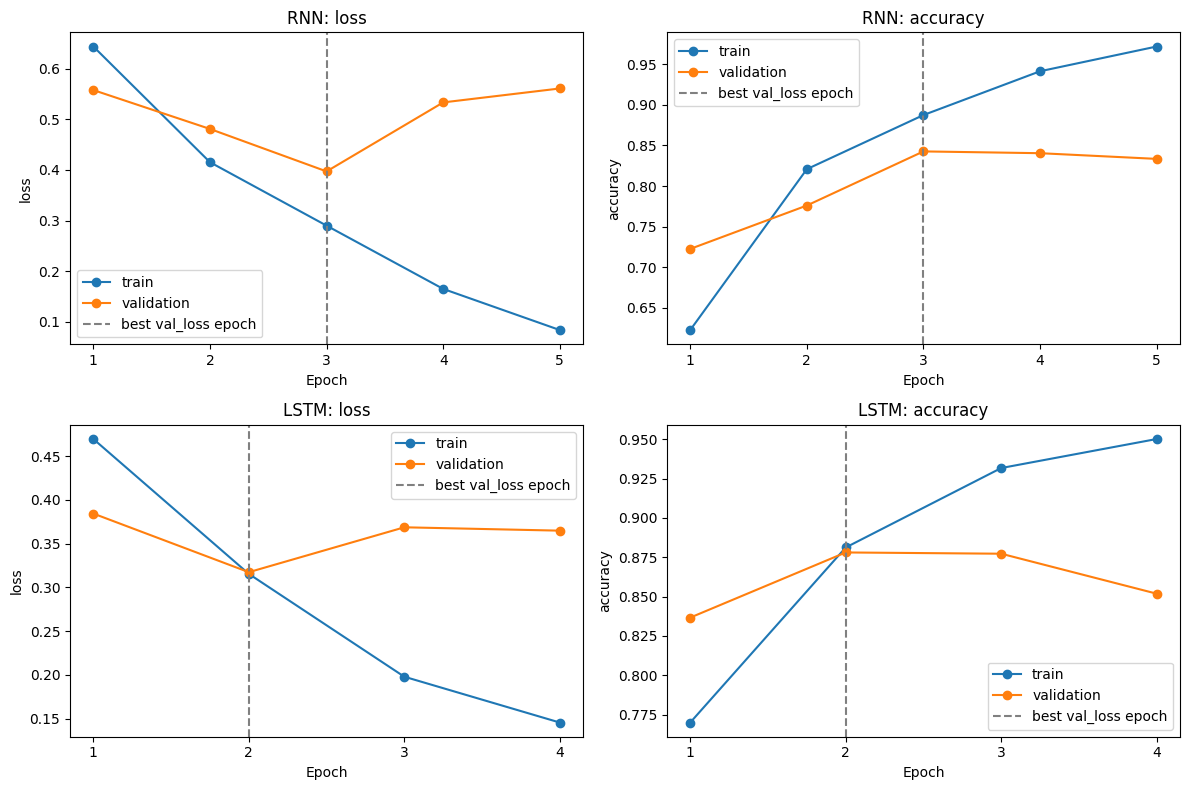

In [7]:
def build_neural_model(kind):
    recurrent = tf.keras.layers.SimpleRNN if kind == "RNN" else tf.keras.layers.LSTM
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        tf.keras.layers.Embedding(len(vectorizer.get_vocabulary()), EMBEDDING_DIM,
                                  mask_zero=True, name="embedding"),
        recurrent(RECURRENT_UNITS, activation="tanh", recurrent_dropout=0.0,
                  name="recurrent"),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ], name=kind)
    model.compile(optimizer=tf.keras.optimizers.Adam(
                      learning_rate=LEARNING_RATE, clipnorm=1.0),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def neural_dataset(features, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((features, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

neural_models, histories = {}, {}
for name in ["RNN", "LSTM"]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_neural_model(name)
    model.summary()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                         restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / f"{name}.keras"),
            monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    start = time.perf_counter()
    history = model.fit(
        neural_dataset(sequence_features["train"], y_train, training=True),
        validation_data=neural_dataset(sequence_features["validation"], y_val),
        epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2)
    elapsed = time.perf_counter() - start
    hist = pd.DataFrame(history.history)
    assert np.isfinite(hist.to_numpy()).all(), "Loss/metric không hữu hạn"
    hist.index = np.arange(1, len(hist) + 1)
    hist.index.name = "epoch"
    hist.to_csv(OUTPUT_DIR / f"history_{name}.csv", encoding="utf-8-sig")
    best_epoch = int(hist.val_loss.idxmin())
    # Load checkpoint chọn bằng validation: khớp trọng số được dùng để đánh giá và xuất.
    best_model = tf.keras.models.load_model(MODEL_DIR / f"{name}.keras")
    # EarlyStopping và checkpoint phải khôi phục cùng trọng số tốt nhất.
    for restored_weight, checkpoint_weight in zip(model.get_weights(), best_model.get_weights()):
        np.testing.assert_allclose(restored_weight, checkpoint_weight, rtol=0, atol=1e-7)
    neural_models[name], histories[name] = best_model, hist
    training_details[name] = {
        "train_seconds": elapsed, "epochs_run": len(hist), "best_epoch": best_epoch,
        "best_validation_loss": float(hist.loc[best_epoch, "val_loss"]),
        "best_validation_accuracy": float(hist.loc[best_epoch, "val_accuracy"]),
        "parameters": int(best_model.count_params()),
        "device": environment["neural_device"],
    }

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, hist) in enumerate(histories.items()):
    for col, metric in enumerate(["loss", "accuracy"]):
        ax = axes[row, col]
        ax.plot(hist.index, hist[metric], marker="o", label="train")
        ax.plot(hist.index, hist["val_" + metric], marker="o", label="validation")
        ax.axvline(training_details[name]["best_epoch"], color="gray", linestyle="--",
                   label="best val_loss epoch")
        ax.set(title=f"{name}: {metric}", xlabel="Epoch", ylabel=metric)
        ax.set_xticks(hist.index)
        ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "learning_curves.png", dpi=160)
plt.show()

## 9. Đánh giá bốn mô hình trên cùng test

Chỉ đến bước này mới tính dự đoán và chỉ số trên test. Không dùng test để chọn
lại C, epoch hoặc ngưỡng. Với positive là lớp 1:

- **TP/TN:** positive/negative được dự đoán đúng.
- **FP:** negative bị dự đoán positive; **FN:** positive bị dự đoán negative.
- **Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$: tỷ lệ dự đoán đúng.
- **Precision** $=TP/(TP+FP)$: độ chính xác trong các dự đoán positive.
- **Recall** $=TP/(TP+FN)$: tỷ lệ positive được phát hiện.
- **F1** $=2PR/(P+R)$: trung bình điều hòa Precision và Recall.
- **ROC-AUC:** khả năng xếp mẫu positive cao hơn negative theo điểm dự đoán,
  xét trên nhiều ngưỡng. Giá trị 0,5 tương ứng xếp hạng ngẫu nhiên.

Ngưỡng phân lớp là 0,5 cho Logistic Regression và hai mạng; 0 cho SVM.
ROC-AUC của SVM dùng `decision_function`, không dùng nhãn cứng; margin này
không phải xác suất. Precision/Recall/F1 được tính cho lớp positive.

Thời gian train tách khỏi tiền xử lý và đánh giá test cuối cùng. Baseline cộng
ba lần fit C, chưa tính bước chấm F1 validation; mạng tính cả validation mỗi
epoch và ghi checkpoint. Đây là chi phí pipeline thực đo, chưa đồng nhất hoàn
toàn về ngân sách chọn mô hình. Thiết bị thực tế được ghi trong bảng kết quả.

Ngoài test chuẩn, báo thêm chỉ số trên phần test có hash văn bản đã làm sạch
không xuất hiện trong train hoặc validation. Đây là kiểm tra phụ về độ nhạy
với nội dung trùng, không dùng để chọn lại mô hình hay thay kết quả benchmark.

,model,run_mode,test_samples,accuracy,precision,recall,f1,roc_auc,train_seconds,predict_seconds,device
0,Logistic Regression,full,25000,0.8988,0.8977,0.9002,0.8990,0.9633,1.7702,0.0199,CPU
1,SVM,full,25000,0.8943,0.8941,0.8945,0.8943,0.9606,2.6933,0.0184,CPU
2,RNN,full,25000,0.8318,0.8501,0.8057,0.8273,0.8929,66.3218,4.0148,CPU
3,LSTM,full,25000,0.8626,0.8567,0.8709,0.8637,0.9326,103.6152,7.6760,CPU


**Kiểm tra phụ: test không trùng chính xác với train/validation sau làm sạch; giữ nguyên mô hình và ngưỡng.**

,model,run_mode,test_samples,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,full,24877,0.8985,0.8978,0.9000,0.8989,0.9631
1,SVM,full,24877,0.8939,0.8941,0.8942,0.8942,0.9603
2,RNN,full,24877,0.8313,0.8504,0.8052,0.8272,0.8925
3,LSTM,full,24877,0.8624,0.8571,0.8707,0.8638,0.9325


,model,tn,fp,fn,tp
0,Logistic Regression,11218,1282,1247,11253
1,SVM,11176,1324,1319,11181
2,RNN,10724,1776,2429,10071
3,LSTM,10679,1821,1614,10886


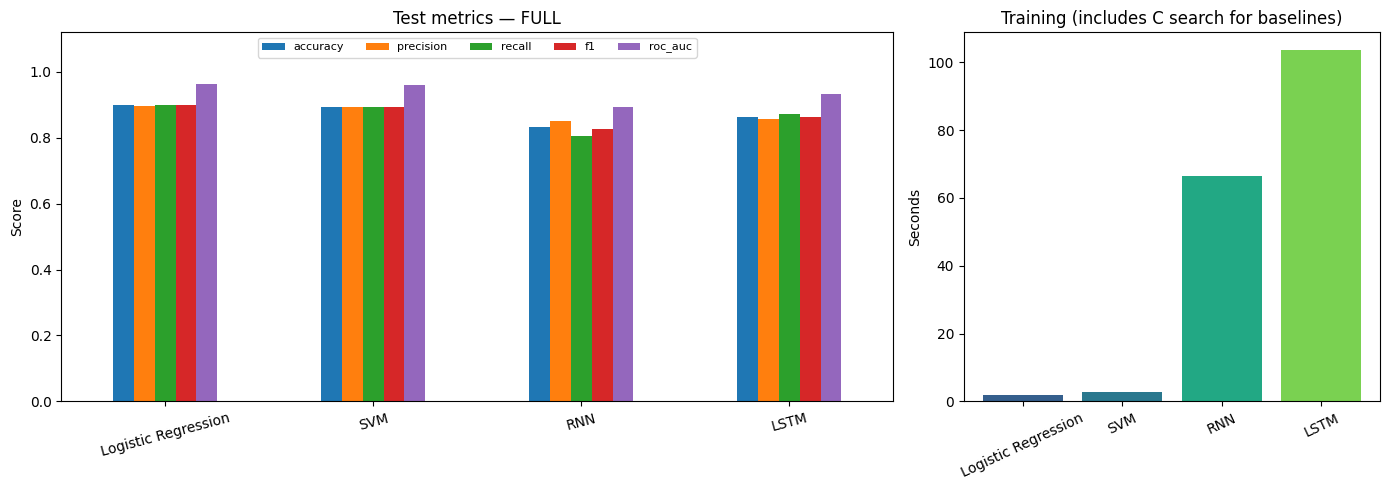

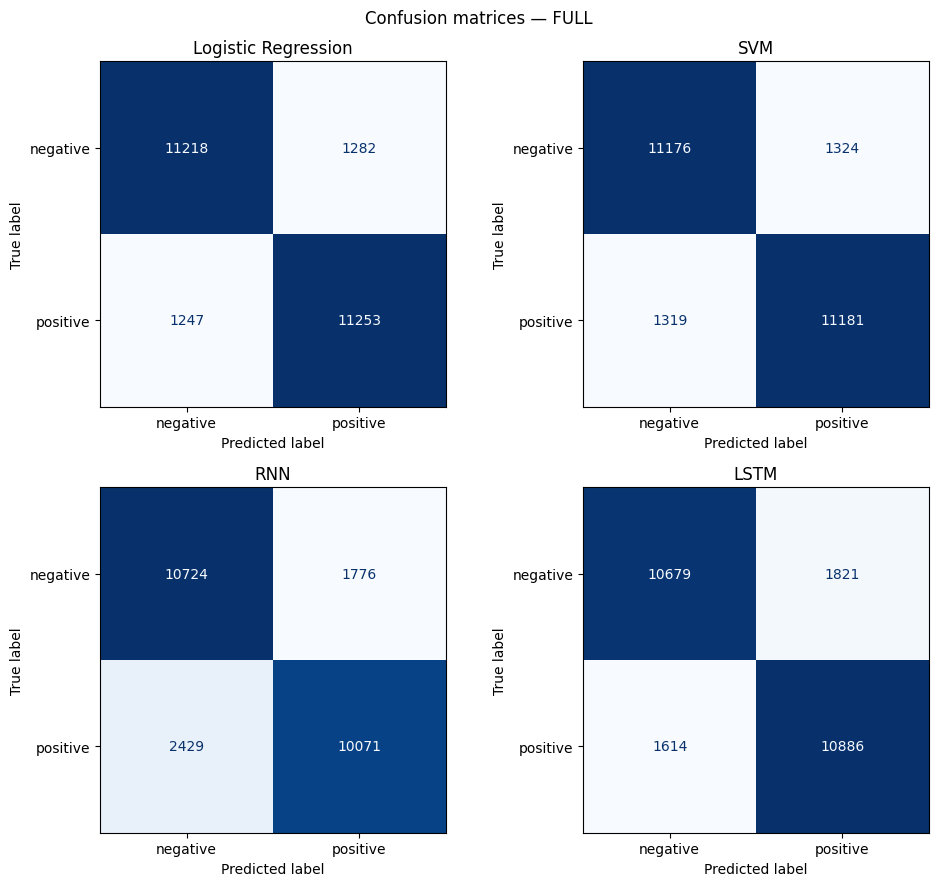

In [8]:
model_order = ["Logistic Regression", "SVM", "RNN", "LSTM"]
metric_rows, test_outputs = [], {}
predictions_df = test_df[["review_id", "label", "n_tokens", "seen_in_development"]].copy()
for name in model_order:
    start = time.perf_counter()
    if name == "SVM":
        scores = baseline_models[name].decision_function(tfidf_features["test"])
        predicted = (scores >= 0).astype(np.int32)
    elif name == "Logistic Regression":
        scores = baseline_models[name].predict_proba(tfidf_features["test"])[:, 1]
        predicted = (scores >= 0.5).astype(np.int32)
    else:
        scores = neural_models[name].predict(sequence_features["test"],
                                             batch_size=BATCH_SIZE, verbose=0).ravel()
        predicted = (scores >= 0.5).astype(np.int32)
    predict_seconds = time.perf_counter() - start
    assert scores.shape == y_test.shape and np.isfinite(scores).all()
    assert set(np.unique(predicted)).issubset({0, 1})
    test_outputs[name] = {"scores": scores, "predicted": predicted}
    metric_rows.append({
        "model": name, "run_mode": RUN_MODE, "test_samples": len(y_test),
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
        "train_seconds": training_details[name]["train_seconds"],
        "predict_seconds": predict_seconds, "device": training_details[name]["device"],
    })
    slug = name.lower().replace(" ", "_")
    predictions_df[slug + "_prediction"] = predicted
    predictions_df[slug + "_score"] = scores
metrics = pd.DataFrame(metric_rows).set_index("model").loc[model_order].reset_index()
assert metrics.shape[0] == 4
assert metrics[["accuracy", "precision", "recall", "f1", "roc_auc"]].apply(
    lambda col: col.between(0, 1).all()).all()
assert metrics.test_samples.eq(len(test_df)).all()
metrics.to_csv(OUTPUT_DIR / "metrics.csv", index=False, encoding="utf-8-sig")
predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
display(metrics.round(4))


confusion_rows, nonoverlap_rows = [], []
nonoverlap_mask = ~test_df.seen_in_development.to_numpy()
assert nonoverlap_mask.any() and set(y_test[nonoverlap_mask]) == {0, 1}
for name in model_order:
    scores, predicted = test_outputs[name]["scores"], test_outputs[name]["predicted"]
    confusion_rows.append({
        "model": name,
        "tn": int(((y_test == 0) & (predicted == 0)).sum()),
        "fp": int(((y_test == 0) & (predicted == 1)).sum()),
        "fn": int(((y_test == 1) & (predicted == 0)).sum()),
        "tp": int(((y_test == 1) & (predicted == 1)).sum()),
    })
    truth, pred, score = y_test[nonoverlap_mask], predicted[nonoverlap_mask], scores[nonoverlap_mask]
    nonoverlap_rows.append({
        "model": name, "run_mode": RUN_MODE, "test_samples": len(truth),
        "accuracy": accuracy_score(truth, pred),
        "precision": precision_score(truth, pred, zero_division=0),
        "recall": recall_score(truth, pred, zero_division=0),
        "f1": f1_score(truth, pred, zero_division=0), "roc_auc": roc_auc_score(truth, score),
    })
confusion_counts = pd.DataFrame(confusion_rows)
nonoverlap_metrics = pd.DataFrame(nonoverlap_rows)
confusion_counts.to_csv(OUTPUT_DIR / "confusion_counts.csv", index=False, encoding="utf-8-sig")
nonoverlap_metrics.to_csv(OUTPUT_DIR / "metrics_nonoverlap.csv", index=False, encoding="utf-8-sig")
display(Markdown("**Kiểm tra phụ: test không trùng chính xác với train/validation sau làm sạch; giữ nguyên mô hình và ngưỡng.**"))
display(nonoverlap_metrics.round(4))
display(confusion_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
metrics.set_index("model")[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot.bar(
    ax=axes[0], rot=15, ylim=(0, 1.12))
axes[0].set(title=f"Test metrics — {RUN_MODE.upper()}", ylabel="Score", xlabel="")
axes[0].legend(loc="upper center", ncol=5, fontsize=8)
axes[1].bar(metrics.model, metrics.train_seconds, color=["#355f8d", "#2a788e", "#22a884", "#7ad151"])
axes[1].tick_params(axis="x", rotation=25)
axes[1].set(title="Training (includes C search for baselines)", ylabel="Seconds")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "comparison.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, name in zip(axes.flat, model_order):
    ConfusionMatrixDisplay.from_predictions(y_test, test_outputs[name]["predicted"],
        labels=[0, 1], display_labels=["negative", "positive"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    ax.set_title(name)
fig.suptitle(f"Confusion matrices — {RUN_MODE.upper()}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices.png", dpi=160)
plt.show()

## 10. Phân tích lỗi và thử dự đoán
Lấy tối đa ba lỗi có điểm dự đoán xa ngưỡng nhất của mỗi mô hình. Điểm SVM và xác suất không cùng thang đo. Thống kê theo độ dài chỉ mô tả tương quan, chưa chứng minh cắt chuỗi gây lỗi. Phủ định, mỉa mai và cảm xúc trái chiều cần đọc từng ví dụ để giải thích.

In [9]:
error_frames, length_rows = [], []
for name in model_order:
    output = test_outputs[name]
    wrong = output["predicted"] != y_test
    errors = test_df.loc[wrong, ["review_id", "text", "label", "n_tokens"]].copy()
    errors["predicted"] = output["predicted"][wrong]
    errors["score"] = output["scores"][wrong]
    errors["distance_from_threshold"] = np.abs(errors.score - (0 if name == "SVM" else 0.5))
    errors["model"] = name
    errors["has_negation"] = errors.text.map(clean_text).str.contains(r"\b(?:not|no|never)\b", regex=True)
    errors["truncated_for_neural"] = errors.n_tokens.gt(SEQUENCE_LENGTH)
    error_frames.append(errors.sort_values("distance_from_threshold", ascending=False).head(3))
    for long_review in [False, True]:
        mask = test_df.n_tokens.gt(SEQUENCE_LENGTH).to_numpy() == long_review
        length_rows.append({"model": name, "length_group": f">{SEQUENCE_LENGTH}" if long_review else f"<={SEQUENCE_LENGTH}",
                            "samples": int(mask.sum()),
                            "error_rate": float(wrong[mask].mean()) if mask.any() else None})
error_examples = pd.concat(error_frames, ignore_index=True)
length_analysis = pd.DataFrame(length_rows)
error_examples.to_csv(OUTPUT_DIR / "error_examples.csv", index=False, encoding="utf-8-sig")
length_analysis.to_csv(OUTPUT_DIR / "errors_by_length.csv", index=False, encoding="utf-8-sig")
display(error_examples.assign(text=error_examples.text.str.slice(0, 240))[
    ["model", "review_id", "label", "predicted", "score", "has_negation", "text"]])
display(length_analysis.round(4))

def predict_reviews(texts):
    if isinstance(texts, str):
        texts = [texts]
    if not texts or any(not isinstance(text, str) or not clean_text(text) for text in texts):
        raise ValueError("Cần ít nhất một đánh giá có nội dung sau khi làm sạch.")
    cleaned = [clean_text(text) for text in texts]
    sparse = tfidf.transform(cleaned)
    sequences = encode_sequences(cleaned)
    rows = []
    for name in model_order:
        if name == "SVM":
            scores = baseline_models[name].decision_function(sparse)
        elif name == "Logistic Regression":
            scores = baseline_models[name].predict_proba(sparse)[:, 1]
        else:
            scores = neural_models[name].predict(sequences, verbose=0).ravel()
        for text, score in zip(texts, scores):
            rows.append({"text": text, "model": name, "score": float(score),
                         "score_type": "margin" if name == "SVM" else "probability",
                         "sentiment": "positive" if score >= (0 if name == "SVM" else 0.5) else "negative"})
    return pd.DataFrame(rows)

display(predict_reviews(["The acting was wonderful and I loved the story.",
                         "I did not enjoy this boring movie at all."]))
assert predict_reviews("A good movie.").shape[0] == 4
try:
    predict_reviews("<br />!!!")
except ValueError:
    pass
else:
    raise AssertionError("Đầu vào trống phải được phát hiện")
# Kiểm tra file mô hình baseline và vocabulary đủ để phục hồi dự đoán.
restored_tfidf = joblib.load(MODEL_DIR / "tfidf.joblib")
restored_baselines = joblib.load(MODEL_DIR / "baseline_classifiers.joblib")
fixture = train_df.clean_text.iloc[:3].tolist()
for name in baseline_models:
    np.testing.assert_array_equal(
        restored_baselines[name].predict(restored_tfidf.transform(fixture)),
        baseline_models[name].predict(tfidf.transform(fixture)))
restored_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS, standardize=None, split="whitespace", output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    vocabulary=json.loads((MODEL_DIR / "vocabulary.json").read_text(encoding="utf-8")))
np.testing.assert_array_equal(restored_vectorizer(tf.constant(fixture)).numpy(), encode_sequences(fixture))
assert all((MODEL_DIR / f"{name}.keras").exists() for name in ["RNN", "LSTM"])
print("Kiểm tra dữ liệu, metric, đầu vào và phục hồi mô hình: PASS")

,model,review_id,label,predicted,score,has_negation,text
0,Logistic Regression,test/04118,0,1,0.998185,True,This is definitely one of the best Kung fu mov...
1,Logistic Regression,test/20621,1,0,0.002030,True,This was Laurel and Hardy's last silent film f...
2,Logistic Regression,test/00776,0,1,0.997538,True,"In all honesty, I haven't seen this film for m..."
3,SVM,test/20621,1,0,-2.088462,True,This was Laurel and Hardy's last silent film f...
4,SVM,test/00776,0,1,1.904874,True,"In all honesty, I haven't seen this film for m..."
5,SVM,test/04118,0,1,1.873529,True,This is definitely one of the best Kung fu mov...
6,RNN,test/08084,0,1,0.992353,True,Two days ago I got a chance to watch this movi...
7,RNN,test/03757,0,1,0.991979,True,"I went to see this 3 nights ago here in Cork, ..."
8,RNN,test/19488,1,0,0.009949,True,"The lovely, yet lethal Alexandra (stunning sta..."
9,LSTM,test/03757,0,1,0.997241,True,"I went to see this 3 nights ago here in Cork, ..."


,model,length_group,samples,error_rate
0,Logistic Regression,<=300,19389,0.1009
1,Logistic Regression,>300,5611,0.1019
2,SVM,<=300,19389,0.1058
3,SVM,>300,5611,0.1053
4,RNN,<=300,19389,0.1508
5,RNN,>300,5611,0.2285
6,LSTM,<=300,19389,0.1234
7,LSTM,>300,5611,0.1859


,text,model,score,score_type,sentiment
0,The acting was wonderful and I loved the story.,Logistic Regression,0.975405,probability,positive
1,I did not enjoy this boring movie at all.,Logistic Regression,0.023029,probability,negative
2,The acting was wonderful and I loved the story.,SVM,1.048285,margin,positive
3,I did not enjoy this boring movie at all.,SVM,-1.221225,margin,negative
4,The acting was wonderful and I loved the story.,RNN,0.890026,probability,positive
5,I did not enjoy this boring movie at all.,RNN,0.262589,probability,negative
6,The acting was wonderful and I loved the story.,LSTM,0.865249,probability,positive
7,I did not enjoy this boring movie at all.,LSTM,0.254314,probability,negative


Kiểm tra dữ liệu, metric, đầu vào và phục hồi mô hình: PASS


## 11. Phân tích kết quả và kết luận

Nhận xét được tạo từ số liệu của lần chạy hiện tại, gồm kiểm tra nội dung trùng, precision/recall và FP/FN. Quick chỉ kiểm tra quy trình; full dùng để kết luận.

In [10]:
def build_results_discussion():
    if RUN_MODE == "quick":
        return (
            "> **KIỂM TRA NHANH:** chỉ dùng để kiểm tra quy trình, không kết luận chất lượng.\n\n"
            f"Đã chạy {len(train_df):,} train / {len(val_df):,} validation / {len(test_df):,} test, "
            f"tối đa {MAX_EPOCHS} epoch, đủ bốn mô hình và các kiểm tra lưu/nạp. "
            "Cần chạy `RUN_MODE = \"full\"` để kết luận bài tập."
        )
    indexed = metrics.set_index("model")
    counts = confusion_counts.set_index("model")
    ranking = indexed.sort_values("f1", ascending=False)
    best = ranking.index[0]
    best_baseline = indexed.loc[["Logistic Regression", "SVM"], "f1"].idxmax()
    best_neural = indexed.loc[["RNN", "LSTM"], "f1"].idxmax()
    paragraphs = ["### 11.1. So sánh trên cùng tập test"]
    paragraphs.append(
        f"Trên {len(test_df):,} mẫu test chuẩn, thứ hạng theo F1 là: "
        + " > ".join(f"{name} ({row.f1:.4f})" for name, row in ranking.iterrows())
        + ". Thứ hạng mô tả cấu hình và seed hiện tại; chưa có kiểm định ý nghĩa thống kê."
    )
    for name in ["Logistic Regression", "SVM"]:
        row, info, errors = indexed.loc[name], training_details[name], counts.loc[name]
        paragraphs.append(
            f"**{name}:** chọn C={info['C']:g} theo F1 validation {info['validation_f1']:.4f}. "
            f"Test Accuracy={row.accuracy:.2%}, Precision={row.precision:.4f}, "
            f"Recall={row.recall:.4f}, F1={row.f1:.4f}, ROC-AUC={row.roc_auc:.4f}. "
            f"Có {int(errors.fp):,} FP và {int(errors.fn):,} FN. "
            f"Tổng thời gian fit {len(C_VALUES)} giá trị C là {row.train_seconds:.2f} giây."
        )
    paragraphs.append(
        f"F1(Logistic Regression) − F1(SVM) = "
        f"**{100*(indexed.loc['Logistic Regression', 'f1']-indexed.loc['SVM', 'f1']):+.2f} điểm phần trăm**. "
        "Hai mô hình cùng dùng TF-IDF, nhưng có hàm mất mát khác nhau và C được chọn riêng cho từng mô hình."
    )
    paragraphs.append("### 11.2. RNN/LSTM và dấu hiệu overfitting")
    for name in ["RNN", "LSTM"]:
        row, info, hist = indexed.loc[name], training_details[name], histories[name]
        selected, last = hist.loc[info["best_epoch"]], hist.iloc[-1]
        overfits = (info["epochs_run"] > info["best_epoch"]
                    and last.val_loss > selected.val_loss and last.loss < selected.loss)
        message = (
            f"Từ epoch được chọn đến epoch cuối, train loss giảm "
            f"{selected.loss:.4f} → {last.loss:.4f}, trong khi validation loss tăng "
            f"{selected.val_loss:.4f} → {last.val_loss:.4f}: dấu hiệu overfitting."
            if overfits else
            "Cần đọc xu hướng learning curves; không kết luận overfitting chỉ từ một chênh lệch train–validation."
        )
        paragraphs.append(
            f"**{name}:** chạy {info['epochs_run']} epoch, chọn epoch {info['best_epoch']} "
            f"theo validation loss={selected.val_loss:.4f}; có {info['parameters']:,} tham số. "
            f"Accuracy train/validation tại epoch đó là {selected.accuracy:.2%}/{selected.val_accuracy:.2%}. "
            f"Test Accuracy={row.accuracy:.2%}, F1={row.f1:.4f}, ROC-AUC={row.roc_auc:.4f}. "
            f"Thời gian fit={row.train_seconds:.2f} giây. {message} Test dùng checkpoint đã nạp lại."
        )
    paragraphs.append(
        "Train metric được ghi khi trọng số đang cập nhật và Dropout bật; validation được tính "
        "sau epoch với Dropout tắt. Hai đường cần được đọc theo xu hướng qua nhiều epoch."
    )
    paragraphs.append(
        f"LSTM − RNN: F1 **{100*(indexed.loc['LSTM', 'f1']-indexed.loc['RNN', 'f1']):+.2f} điểm phần trăm**, "
        f"Precision {100*(indexed.loc['LSTM', 'precision']-indexed.loc['RNN', 'precision']):+.2f} điểm, "
        f"Recall positive {100*(indexed.loc['LSTM', 'recall']-indexed.loc['RNN', 'recall']):+.2f} điểm. "
        f"Số FP thay đổi {int(counts.loc['LSTM', 'fp']-counts.loc['RNN', 'fp']):+,}; "
        f"FN thay đổi {int(counts.loc['LSTM', 'fn']-counts.loc['RNN', 'fn']):+,}. "
        "Đây là mô tả dự đoán thực tế, chưa chứng minh cơ chế nhớ là nguyên nhân của chênh lệch."
    )
    for name in ["RNN", "LSTM"]:
        delta = 100 * (indexed.loc[name, "f1"] - indexed.loc[best_baseline, "f1"])
        paragraphs.append(f"F1({name}) − F1(baseline tốt nhất, {best_baseline}) = **{delta:+.2f} điểm phần trăm**.")
    paragraphs.append("### 11.3. Độ dài, nội dung trùng và phân tích lỗi")
    truncated = int(test_df.n_tokens.gt(SEQUENCE_LENGTH).sum())
    paragraphs.append(
        f"Có {truncated:,}/{len(test_df):,} đánh giá test ({truncated/len(test_df):.2%}) "
        f"dài hơn {SEQUENCE_LENGTH} token. TF-IDF dùng toàn văn, còn hai mạng giữ "
        f"{SEQUENCE_LENGTH} token đầu. Hai biểu diễn có khác biệt về thông tin đầu vào."
    )
    for name in model_order:
        groups = length_analysis[length_analysis.model.eq(name)].set_index("length_group")
        short_rate = groups.loc[f"<={SEQUENCE_LENGTH}", "error_rate"]
        long_rate = groups.loc[f">{SEQUENCE_LENGTH}", "error_rate"]
        if pd.notna(short_rate) and pd.notna(long_rate):
            paragraphs.append(
                f"{name}: tỷ lệ lỗi nhóm ≤{SEQUENCE_LENGTH} token {short_rate:.2%}, "
                f"nhóm >{SEQUENCE_LENGTH} token {long_rate:.2%} "
                f"(chênh lệch {100*(long_rate-short_rate):+.2f} điểm phần trăm)."
            )
    paragraphs.append(
        "Các nhóm độ dài có thể khác độ khó; tỷ lệ lỗi theo độ dài chỉ là tương quan, "
        "chưa chứng minh việc cắt chuỗi gây ra lỗi. Cần thí nghiệm đối chứng cùng giới hạn đầu vào."
    )
    for row in content_overlap[content_overlap.representation.eq("clean")].itertuples(index=False):
        paragraphs.append(
            f"Trùng nội dung sau làm sạch {row.left_split}–{row.right_split}: "
            f"{row.shared_unique_texts} văn bản duy nhất, liên quan {row.left_rows} hàng "
            f"ở {row.left_split} và {row.right_rows} hàng ở {row.right_split}."
        )
    seen = int(test_df.seen_in_development.sum())
    auxiliary = nonoverlap_metrics.set_index("model")
    auxiliary_order = auxiliary.sort_values("f1", ascending=False).index.tolist()
    paragraphs.append(
        f"Có {seen:,}/{len(test_df):,} hàng test ({seen/len(test_df):.2%}) trùng nội dung "
        "với train hoặc validation. Giữ split chuẩn để đối chiếu benchmark; các tập vì vậy "
        "chưa độc lập hoàn toàn về nội dung. Kiểm tra phụ loại các hàng này khỏi phần chấm điểm "
        f"test, còn {int(auxiliary.test_samples.iloc[0]):,} hàng, giữ nguyên mô hình/ngưỡng. "
        + "F1: " + "; ".join(f"{name}={auxiliary.loc[name, 'f1']:.4f}" for name in model_order)
        + ". Thứ hạng " + ("giữ nguyên." if auxiliary_order == ranking.index.tolist() else "thay đổi ở kiểm tra phụ.")
        + " Kiểm tra phụ này không loại trùng bên trong test hoặc giải quyết trùng train–validation."
    )
    paragraphs.append(
        f"Phần 10 chọn {len(error_examples)} trường hợp sai thuộc "
        f"{error_examples.review_id.nunique()} bài đánh giá duy nhất; một bài có thể bị nhiều mô hình "
        "dự đoán sai. Đây là các lỗi có điểm xa ngưỡng, không phải mẫu ngẫu nhiên đại diện mọi lỗi. "
        "Điểm SVM và xác suất khác thang đo; dấu hiệu phủ định không tự chứng minh nguyên nhân sai."
    )
    paragraphs.append("### 11.4. Kết luận và giới hạn")
    paragraphs.append(
        f"**Trong cấu hình và seed hiện tại, {best} đạt F1 cao nhất** trên test chuẩn "
        f"(F1={indexed.loc[best, 'f1']:.4f}, Accuracy={indexed.loc[best, 'accuracy']:.2%}). "
        f"Trong hai mạng hồi tiếp được thử, {best_neural} đạt F1 cao nhất. "
        "TF-IDF unigram/bigram giữ tín hiệu từ/cụm từ; mạng học embedding từ đầu và chỉ đọc phần đầu. "
        "LSTM có cơ chế hỗ trợ phụ thuộc xa nhưng điều đó không bảo đảm thắng baseline."
    )
    paragraphs.append(
        "Chưa cô lập ảnh hưởng kiến trúc: khác biểu diễn, độ dài đầu vào, số tham số và "
        "tiêu chí chọn mô hình (F1 validation cho baseline, validation loss cho mạng). "
        "Mới chạy một seed, chưa đo độ biến thiên hoặc kiểm định ý nghĩa thống kê. "
        "Nội dung trùng giữa các tập cũng giới hạn mức độc lập của đánh giá. "
        "Không chỉnh tham số hay ngưỡng theo test vừa quan sát."
    )
    paragraphs.append(
        "Thời gian baseline cộng các lần fit C, chưa gồm chấm F1 validation; thời gian mạng "
        "gồm validation mỗi epoch và ghi checkpoint. Tiền xử lý được ghi riêng. "
        "Cần đọc cùng thiết bị trong environment.json; các số này không chứng minh độ phức tạp "
        "thuật toán hay chi phí pipeline được đồng nhất hoàn toàn. Hướng nghiên cứu tiếp theo "
        "là nhiều seed, cùng giới hạn đầu vào, chia nhóm theo nội dung và embedding tiền huấn luyện; "
        "các thí nghiệm đó chưa được thực hiện."
    )
    return "\n\n".join(paragraphs)

discussion = build_results_discussion()
display(Markdown(discussion))

### 11.1. So sánh trên cùng tập test

Trên 25,000 mẫu test chuẩn, thứ hạng theo F1 là: Logistic Regression (0.8990) > SVM (0.8943) > LSTM (0.8637) > RNN (0.8273). Thứ hạng mô tả cấu hình và seed hiện tại; chưa có kiểm định ý nghĩa thống kê.

**Logistic Regression:** chọn C=10 theo F1 validation 0.9063. Test Accuracy=89.88%, Precision=0.8977, Recall=0.9002, F1=0.8990, ROC-AUC=0.9633. Có 1,282 FP và 1,247 FN. Tổng thời gian fit 3 giá trị C là 1.77 giây.

**SVM:** chọn C=1 theo F1 validation 0.9071. Test Accuracy=89.43%, Precision=0.8941, Recall=0.8945, F1=0.8943, ROC-AUC=0.9606. Có 1,324 FP và 1,319 FN. Tổng thời gian fit 3 giá trị C là 2.69 giây.

F1(Logistic Regression) − F1(SVM) = **+0.47 điểm phần trăm**. Hai mô hình cùng dùng TF-IDF, nhưng có hàm mất mát khác nhau và C được chọn riêng cho từng mô hình.

### 11.2. RNN/LSTM và dấu hiệu overfitting

**RNN:** chạy 5 epoch, chọn epoch 3 theo validation loss=0.3970; có 2,572,417 tham số. Accuracy train/validation tại epoch đó là 88.74%/84.26%. Test Accuracy=83.18%, F1=0.8273, ROC-AUC=0.8929. Thời gian fit=66.32 giây. Từ epoch được chọn đến epoch cuối, train loss giảm 0.2899 → 0.0836, trong khi validation loss tăng 0.3970 → 0.5608: dấu hiệu overfitting. Test dùng checkpoint đã nạp lại.

**LSTM:** chạy 4 epoch, chọn epoch 2 theo validation loss=0.3174; có 2,609,473 tham số. Accuracy train/validation tại epoch đó là 88.12%/87.80%. Test Accuracy=86.26%, F1=0.8637, ROC-AUC=0.9326. Thời gian fit=103.62 giây. Từ epoch được chọn đến epoch cuối, train loss giảm 0.3154 → 0.1456, trong khi validation loss tăng 0.3174 → 0.3648: dấu hiệu overfitting. Test dùng checkpoint đã nạp lại.

Train metric được ghi khi trọng số đang cập nhật và Dropout bật; validation được tính sau epoch với Dropout tắt. Hai đường cần được đọc theo xu hướng qua nhiều epoch.

LSTM − RNN: F1 **+3.64 điểm phần trăm**, Precision +0.66 điểm, Recall positive +6.52 điểm. Số FP thay đổi +45; FN thay đổi -815. Đây là mô tả dự đoán thực tế, chưa chứng minh cơ chế nhớ là nguyên nhân của chênh lệch.

F1(RNN) − F1(baseline tốt nhất, Logistic Regression) = **-7.17 điểm phần trăm**.

F1(LSTM) − F1(baseline tốt nhất, Logistic Regression) = **-3.53 điểm phần trăm**.

### 11.3. Độ dài, nội dung trùng và phân tích lỗi

Có 5,611/25,000 đánh giá test (22.44%) dài hơn 300 token. TF-IDF dùng toàn văn, còn hai mạng giữ 300 token đầu. Hai biểu diễn có khác biệt về thông tin đầu vào.

Logistic Regression: tỷ lệ lỗi nhóm ≤300 token 10.09%, nhóm >300 token 10.19% (chênh lệch +0.10 điểm phần trăm).

SVM: tỷ lệ lỗi nhóm ≤300 token 10.58%, nhóm >300 token 10.53% (chênh lệch -0.05 điểm phần trăm).

RNN: tỷ lệ lỗi nhóm ≤300 token 15.08%, nhóm >300 token 22.85% (chênh lệch +7.77 điểm phần trăm).

LSTM: tỷ lệ lỗi nhóm ≤300 token 12.34%, nhóm >300 token 18.59% (chênh lệch +6.25 điểm phần trăm).

Các nhóm độ dài có thể khác độ khó; tỷ lệ lỗi theo độ dài chỉ là tương quan, chưa chứng minh việc cắt chuỗi gây ra lỗi. Cần thí nghiệm đối chứng cùng giới hạn đầu vào.

Trùng nội dung sau làm sạch train–validation: 36 văn bản duy nhất, liên quan 38 hàng ở train và 37 hàng ở validation.

Trùng nội dung sau làm sạch train–test: 99 văn bản duy nhất, liên quan 99 hàng ở train và 99 hàng ở test.

Trùng nội dung sau làm sạch validation–test: 24 văn bản duy nhất, liên quan 24 hàng ở validation và 24 hàng ở test.

Có 123/25,000 hàng test (0.49%) trùng nội dung với train hoặc validation. Giữ split chuẩn để đối chiếu benchmark; các tập vì vậy chưa độc lập hoàn toàn về nội dung. Kiểm tra phụ loại các hàng này khỏi phần chấm điểm test, còn 24,877 hàng, giữ nguyên mô hình/ngưỡng. F1: Logistic Regression=0.8989; SVM=0.8942; RNN=0.8272; LSTM=0.8638. Thứ hạng giữ nguyên. Kiểm tra phụ này không loại trùng bên trong test hoặc giải quyết trùng train–validation.

Phần 10 chọn 12 trường hợp sai thuộc 8 bài đánh giá duy nhất; một bài có thể bị nhiều mô hình dự đoán sai. Đây là các lỗi có điểm xa ngưỡng, không phải mẫu ngẫu nhiên đại diện mọi lỗi. Điểm SVM và xác suất khác thang đo; dấu hiệu phủ định không tự chứng minh nguyên nhân sai.

### 11.4. Kết luận và giới hạn

**Trong cấu hình và seed hiện tại, Logistic Regression đạt F1 cao nhất** trên test chuẩn (F1=0.8990, Accuracy=89.88%). Trong hai mạng hồi tiếp được thử, LSTM đạt F1 cao nhất. TF-IDF unigram/bigram giữ tín hiệu từ/cụm từ; mạng học embedding từ đầu và chỉ đọc phần đầu. LSTM có cơ chế hỗ trợ phụ thuộc xa nhưng điều đó không bảo đảm thắng baseline.

Chưa cô lập ảnh hưởng kiến trúc: khác biểu diễn, độ dài đầu vào, số tham số và tiêu chí chọn mô hình (F1 validation cho baseline, validation loss cho mạng). Mới chạy một seed, chưa đo độ biến thiên hoặc kiểm định ý nghĩa thống kê. Nội dung trùng giữa các tập cũng giới hạn mức độc lập của đánh giá. Không chỉnh tham số hay ngưỡng theo test vừa quan sát.

Thời gian baseline cộng các lần fit C, chưa gồm chấm F1 validation; thời gian mạng gồm validation mỗi epoch và ghi checkpoint. Tiền xử lý được ghi riêng. Cần đọc cùng thiết bị trong environment.json; các số này không chứng minh độ phức tạp thuật toán hay chi phí pipeline được đồng nhất hoàn toàn. Hướng nghiên cứu tiếp theo là nhiều seed, cùng giới hạn đầu vào, chia nhóm theo nội dung và embedding tiền huấn luyện; các thí nghiệm đó chưa được thực hiện.

## 12. Lưu kết quả và khả năng tái lập

Kết quả phụ trợ lưu riêng theo `RUN_MODE` trong `results/full/` hoặc `results/quick/`:

| Tệp/thư mục | Nội dung |
|---|---|
| `metrics.csv`, `test_predictions.csv` | Chỉ số và dự đoán trên test chuẩn |
| `metrics_nonoverlap.csv`, `content_overlap.csv` | Kiểm tra phụ test không trùng train/validation và kiểm kê trùng nội dung |
| `confusion_counts.csv` | TN, FP, FN, TP của từng mô hình |
| `baseline_validation.csv`, `history_*.csv` | Chọn C và lịch sử huấn luyện mạng |
| `data_summary.csv`, `split_manifest.csv` | Cân bằng nhãn, độ dài, ID của từng tập |
| `error_examples.csv`, `errors_by_length.csv` | Ví dụ sai và tỷ lệ lỗi theo độ dài |
| `config.json` | Seed, kích thước tập, siêu tham số và checkpoint được chọn |
| `environment.json` | Python/thư viện, phần cứng, URL và SHA-256 nguồn dữ liệu |
| `checks.json` | Kiểm tra chia tập, vocabulary, metric và phục hồi mô hình |
| `figures/`, `models/` | Hình PNG, TF-IDF, classifier, vocabulary và checkpoint Keras |

Seed 42 và deterministic ops hỗ trợ tái lập trên cùng môi trường; khác phiên
bản thư viện hoặc phần cứng vẫn có thể làm số đo thay đổi. Giữ các file nguồn,
checksum, ID chia tập và phiên bản để đối chiếu. Phần nhận xét ngay phía trên
được tạo từ số liệu của lần chạy hiện tại, không cần một tài liệu báo cáo riêng.

ZIP được tạo trong `results/`, có thể mở/giải nén bằng File Explorer. Chạy tự động
tại thư mục gốc dự án bằng `python scripts/run_full.py` sẽ cập nhật output ngay
trong notebook chính. `python scripts/run_quick_check.py` kiểm tra trong bộ nhớ
và lưu số liệu quick trong `results/quick/`. Dự án chỉ giữ một notebook chính;
các thư mục kết quả và ZIP chứa số liệu, hình ảnh, cấu hình và mô hình.

In [11]:
config = {
    "run_mode": RUN_MODE, "seed": SEED, "max_tokens": MAX_TOKENS,
    "sequence_length": SEQUENCE_LENGTH, "embedding_dim": EMBEDDING_DIM,
    "recurrent_units": RECURRENT_UNITS, "dropout": DROPOUT, "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "learning_rate": LEARNING_RATE, "clipnorm": 1.0,
    "early_stopping": {"monitor": "val_loss", "patience": 2, "restore_best_weights": True},
    "C_values": C_VALUES, "tfidf": {"ngram_range": [1, 2], "min_df": 2,
    "sublinear_tf": True, "max_features": MAX_TOKENS},
    "split_sizes": {split: len(frame) for split, frame in splits.items()},
    "vocabulary_size": len(vectorizer.get_vocabulary()), "tfidf_dimensions": len(tfidf.vocabulary_),
    "selection": training_details, "feature_timing": feature_timing,
    "content_integrity": {"cross_split_overlap": content_overlap.to_dict("records"),
                          "test_seen_in_development": int(test_df.seen_in_development.sum()),
                          "nonoverlap_test_samples": int((~test_df.seen_in_development).sum())},
    "preprocessing": "HTML unescape/strip; lowercase; expand n't; ASCII letters/digits; whitespace",
}
(OUTPUT_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "checks.json").write_text(json.dumps({
    "run_mode": RUN_MODE, "official_dataset_counts": "PASS", "stratification": "PASS",
    "split_ids_disjoint": "PASS", "train_only_vocabulary_sentinel": "PASS",
    "right_padding": "PASS", "finite_metrics": "PASS", "four_models": "PASS",
    "content_overlap_audited": "PASS", "nonoverlap_test_evaluated": "PASS",
    "reload_baselines": "PASS", "reload_neural_checkpoints": "PASS",
    "reload_vocabulary": "PASS", "empty_input": "PASS",
}, indent=2), encoding="utf-8")
zip_base = PROJECT_DIR / "results" / f"IMDB_{RUN_MODE}_results"
zip_path = Path(shutil.make_archive(str(zip_base), "zip", root_dir=OUTPUT_DIR))
print("Kết quả được lưu tại:", OUTPUT_DIR)
print("ZIP:", zip_path, f"({zip_path.stat().st_size / 1024**2:.1f} MB)")
display(Markdown("**Hoàn tất.** Phân tích và kết luận được trình bày trong notebook. Nhấn Ctrl+S để lưu output."))
display(FileLink(str(zip_path.relative_to(PROJECT_DIR))))

Kết quả được lưu tại: D:\Machine Learning\Assignment_NLP_RNN_LSTM_GRU\results\full
ZIP: D:\Machine Learning\Assignment_NLP_RNN_LSTM_GRU\results\IMDB_full_results.zip (57.3 MB)


**Hoàn tất.** Phân tích và kết luận được trình bày trong notebook. Nhấn Ctrl+S để lưu output.

D:\Machine Learning\Assignment_NLP_RNN_LSTM_GRU\results\IMDB_full_results.zip